# Wheat hyperspectral pipeline — v7.2

Stages **1, 2, 2a, 3, 4** are independent. Stage 3 processes masks, mean spectra, selected indices, pixel index maps and **spatial** PCA; **comparative** PCA/K-means, collages and plots are produced only in Stage 4, grouped by observation date.

- **Stage 1:** dark / ArUco / flat-field / Spectralon / optional iris factor -> float16 corrected cube
- **Stage 2:** SegFormer or interactive SAM editing
- **Stage 2a:** edit masks via points (SAM1), optional SAM3 text, HSV V + HSV hue threshold, paint/erase/undo/save
- **Stage 3:** raw and S-G spectra + each mean-normalized; chosen spectral variant for indices, raw cube maps, spatial PCA
- **Stage 4:** grouping by genotype, environment and date; date-specific index collages, comparative PCA, mean spectra with SD and index box/scatter plots

**Hue naming:** `HSV hue` (degrees from RGB segmentation preview) is only a mask tool. `Hue_LCh` is CIELCh(ab) spectral hue computed from original reflectance under D65, 400–780 nm. These are different variables.

Mean-normalized spectra are suitable for shape comparisons; reflectance-scale indices with additive constants or inverse reflectance may lose their usual physical interpretation when calculated on mean-normalized data. `Hue_LCh` is always derived from raw calibrated reflectance, whatever spectral variant is selected.

Interactive editing requires `%matplotlib widget` (`ipympl`).


## Stage 0 — install libraries (Python 3.13.9)
Run once, then **restart the kernel**.

In [1]:
# Установка всех внешних библиотек для пайплайна (Python 3.13.9, 64-bit).
# Запустить ОДИН раз в новом окружении Jupyter, затем перезапустить kernel.
# Важно: устанавливаем пакеты в интерпретатор, используемый этим ноутбуком.
import sys
import platform
import subprocess
from importlib.metadata import version, PackageNotFoundError

if sys.version_info[:2] != (3, 13):
    raise RuntimeError(
        f"Требуется Python 3.13.x (проверено для 3.13.9); "
        f"текущая версия: {sys.version.split()[0]}"
    )
if sys.maxsize <= 2**32:
    raise RuntimeError("Необходим 64-битный Python для PyTorch.")

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)

# Выбери способ установки PyTorch:
# 'cpu'   — работает без NVIDIA GPU (самый универсальный вариант)
# 'cu126' — NVIDIA GPU + подходящий драйвер CUDA 12.6
# 'cu130' — NVIDIA GPU + подходящий драйвер CUDA 13.0
# 'cu132' — NVIDIA GPU + подходящий драйвер CUDA 13.2
TORCH_BACKEND = 'cpu'


def pip_install(*packages):
    cmd = [sys.executable, '-m', 'pip', 'install', '--prefer-binary', *packages]
    print('\n>', ' '.join(cmd), flush=True)
    subprocess.check_call(cmd)


# Обновление инструментов установки.
pip_install('--upgrade', 'pip', 'setuptools', 'wheel')

# Численные расчёты, таблицы, изображения, графики, PCA, Jupyter.
pip_install(
    'numpy>=2.1,<3',
    'pandas>=2.2,<4',
    'matplotlib>=3.9,<4',
    'seaborn>=0.13.2,<1',
    'scikit-learn>=1.6,<2',
    'Pillow>=11,<13',
    'opencv-contrib-python>=4.11,<5',  # cv2.aruco + OpenCV GUI
    'jupyterlab>=4,<5',
    'ipykernel>=6.29,<8',
    'scipy>=1.15,<2',
    'ipywidgets>=8.1,<9',
    'colour-science>=0.4.6,<1',  # spectral CIELCh Hue_LCh, CIE 1931 2-degree / D65
    'ipympl>=0.9.7,<1',
)

# Совместимая пара PyTorch/TorchVision с поддержкой Python 3.13.
torch_packages = ('torch==2.14.1', 'torchvision==0.29.1')
if platform.system() in ('Windows', 'Linux'):
    if TORCH_BACKEND not in ('cpu', 'cu126', 'cu130', 'cu132'):
        raise ValueError('TORCH_BACKEND: cpu, cu126, cu130 или cu132')
    pip_install(*torch_packages,
                '--index-url', f'https://download.pytorch.org/whl/{TORCH_BACKEND}')
elif TORCH_BACKEND == 'cpu':
    # macOS: обычные пакеты PyPI (в том числе Apple Silicon).
    pip_install(*torch_packages)
else:
    raise ValueError('CUDA-варианты этого блока предназначены для Windows/Linux с NVIDIA GPU')

# Совместимая с текущим кодом SegFormer ветка Transformers 4.x.
pip_install('transformers==4.57.6', 'safetensors>=0.5,<1')

print('\nУстановленные версии:')
for package in ('numpy', 'pandas', 'opencv-contrib-python', 'matplotlib',
                'seaborn', 'scikit-learn', 'Pillow', 'torch',
                'torchvision', 'transformers', 'safetensors', 'ipykernel', 'colour-science'):
    try:
        print(f'  {package}: {version(package)}')
    except PackageNotFoundError:
        print(f'  {package}: НЕ УСТАНОВЛЕН')

print('\nГотово. Перезапусти Jupyter kernel (Kernel → Restart Kernel),')
print('после чего выполняй остальные ячейки сверху вниз.')
print('Модель GlobalWheat/GWFSS_Segformer_b0 будет скачана при первом запуске сегментации.')

Python: 3.13.9
Interpreter: c:\anaconda3\python.exe

> c:\anaconda3\python.exe -m pip install --prefer-binary --upgrade pip setuptools wheel

> c:\anaconda3\python.exe -m pip install --prefer-binary numpy>=2.1,<3 pandas>=2.2,<4 matplotlib>=3.9,<4 seaborn>=0.13.2,<1 scikit-learn>=1.6,<2 Pillow>=11,<13 opencv-contrib-python>=4.11,<5 jupyterlab>=4,<5 ipykernel>=6.29,<8 scipy>=1.15,<2 ipywidgets>=8.1,<9 colour-science>=0.4.6,<1 ipympl>=0.9.7,<1

> c:\anaconda3\python.exe -m pip install --prefer-binary torch==2.14.1 torchvision==0.29.1 --index-url https://download.pytorch.org/whl/cpu

> c:\anaconda3\python.exe -m pip install --prefer-binary transformers==4.57.6 safetensors>=0.5,<1

Установленные версии:
  numpy: 2.2.6
  pandas: 2.3.0
  opencv-contrib-python: 4.14.0.94
  matplotlib: 3.10.3
  seaborn: 0.13.2
  scikit-learn: 1.7.2
  Pillow: 11.3.0
  torch: 2.14.1+cpu
  torchvision: 0.29.1+cpu
  transformers: 4.57.6
  safetensors: 0.8.0
  ipykernel: 6.31.0
  colour-science: 0.4.7

Готово. Перез

## Configuration — studies, calibration and analysis options

In [1]:
from pathlib import Path
from process_wheat_study import process_wheat_study
from hyperspectral_masks import segment_samples, edit_mask, list_object_masks
from hyperspectral_object_analysis import analyze_study_objects, find_samples, render_object_index_maps
from hyperspectral_pca_maps import generate_pca_maps
from index_presets import resolve_indices, PRESETS

STUDY_ROOT = Path.cwd()  # parent folder containing one or more studies
selected_folders = [p for p in sorted(STUDY_ROOT.iterdir()) if p.is_dir()
                    and any(p.rglob('Spectral_Cube'))]
# Or choose explicitly:
# selected_folders = [Path(r'D:\Wheat_studies\Study_01')]
print('Study folders:', [p.name for p in selected_folders])

MARKERS = dict(calibration_marker='calibration_target', spectralon_marker='spectralon',
               flat_marker='flat',dark_marker='dark',exclude_marker='#')
OPTIONS = dict(
    use_dark_correction=True,
    dark_subtraction_mode='pixelwise', # 'scalar' is also available
    use_iris_correction=True,  # apply only with one folder containing each iris marker
    iris_open_marker='open_iris',
    iris_closed_marker='closed_iris',
    iris_stability_cv_warning=0.10,  # warn if spectral CV exceeds 10%
    iris_valid_dn_range=(10, 245),  # BOTH images: exclude pixels outside 10..245 DN
    iris_wavelength_range=(500, 700),  # inclusive; None = all wavelengths
    use_alignment=True,
    use_spatial_correction=True,
    use_spectral_correction=True,
    flat_is_spectralon=False,
    reference_wavelength=700,
    spectralon_wavelength=400,
    min_flat_fraction=0.01,
    save_float_cube=True,
    cube_dtype='float16',
    rgb_wavelengths=(630,530,470),
    reuse_existing=True,
    overwrite_existing=True,
    continue_on_error=True,
    show_plot=False,
)
SEGMENTATION_MODEL = 'sam'  # 'segformer', 'sam', 'sam2', 'sam3', 'none'
# 'sam3' uses the separately installed official Meta SAM3 for text prompts.
# SAM1 point prompts remain available in 'sam' mode; SAM2 text prompts are not supported.
SEGFORMER_CLASSES = ('leaf','stem')  # whole tillering plant; change if needed
MASK_MODE = 'individual'          # table/spectra: 'individual' | 'union' | 'full'
MAP_MODE = 'individual'           # maps: 'individual' | 'union' | 'full' | None
INDEX_PRESET = 'medium'           # minimal=8, medium=20, maximum=34 indices (CSIB + Hue_LCh)
CUSTOM_INDICES = None            # e.g. ['NDVI', 'NDRE', 'WBI'] overrides preset
SELECTED_INDICES = resolve_indices(INDEX_PRESET, CUSTOM_INDICES)
print('Vegetation indices:', INDEX_PRESET, len(SELECTED_INDICES), SELECTED_INDICES)
SPECTRAL_VARIANT = 'raw_normalized'  # raw | raw_normalized | savgol | savgol_normalized
PCA_COMPONENTS = 8               # PC01...PC08 plus RGB_PC1_2_3...RGB_PC6_7_8
PCA_MAP_MODE = None              # None -> MASK_MODE, or 'individual'/'union'/'full'
SG_WINDOW,SG_POLYORDER=9,2      # samples in wavelength dimension; window odd
EMPIRICAL_STRATEGY='robust'       # robust or extrema; fixed bounds stay fixed
HISTOGRAM_BINS=10                # equal-width bins between each object's valid index min/max
from index_color_scales import DEFAULT_CONFIG
COLOR_SCALE_CSV = DEFAULT_CONFIG
print('Color configuration:',COLOR_SCALE_CSV)


Study folders: ['data', 'object_analysis_ai']
Vegetation indices: medium 22 ['NDVI', 'NDRE', 'PRI', 'PSRI', 'ARI2', 'CRI2', 'WBI', 'OSAVI', 'GNDVI', 'CIgreen', 'CIrededge', 'NDVI705', 'MTCI', 'SIPI', 'REP', 'mND705', 'TCARI_OSAVI', 'MSAVI', 'CSIB', 'EWRI_410_900', 'EWRI_410_950', 'Hue_LCh']
Color configuration: D:\HS-heat-drought-peas_06.11.2026\index_color_ranges.csv


## Optional aperture calibration — compare open/closed iris references

Run this cell **after configuration, before Stage 1** to obtain the study-level coefficient and a per-wavelength stability plot. It finds exactly one folder whose **name contains** `open_iris` and exactly one whose **name contains** `closed_iris` (case-insensitive) in each study. Each can contain a `Spectral_Cube` subfolder or the spectral image files directly. Names may have prefixes or suffixes (for example, `reference_open_iris_01`), but **only one folder per marker** is allowed in each study. All series must image the **same stationary target**, under identical lighting, exposure, gain and camera settings; only the iris changes. Only pixels that fall between 10 and 245 DN in **both** 8-bit images are compared (the limits scale proportionally for 16-bit images). An additional target-brightness filter excludes dark background. Only wavelengths in `OPTIONS['iris_wavelength_range']` (default 500–700 nm, inclusive) contribute to the single global coefficient. Other usable bands appear on the diagnostic plot but do not affect the result.

The multiplier is **closed/open** because objects are photographed with the open iris and Spectralon/flat references with the closed iris. Stage 1 automatically reads or computes this coefficient if `OPTIONS['use_iris_correction']` is True; rerunning this cell is only needed to *view the diagnostics*. If no complete pair is found, Stage 1 prints a warning and proceeds without the correction. Reports appear in the study root as `iris_correction_by_pair.csv`, `iris_correction_by_wavelength.csv`, `iris_correction_report.json`, and `iris_correction_spectrum.png`.

A strongly wavelength-dependent ratio or unequal illumination means **one scalar may be inadequate**. This correction does not make JPEG values fully radiometrically linear and does not replace controlled acquisition conditions.


In [2]:
from iris_aperture_calibration import calculate_iris_correction

if OPTIONS['use_iris_correction']:
    for study in selected_folders:
        print('IRIS CALIBRATION:', study)
        iris_result = calculate_iris_correction(
            study,
            open_marker=OPTIONS['iris_open_marker'],
            closed_marker=OPTIONS['iris_closed_marker'],
            stability_cv_warning=OPTIONS['iris_stability_cv_warning'],
            valid_dn_range=OPTIONS['iris_valid_dn_range'],
            wavelength_range=OPTIONS['iris_wavelength_range'],
            overwrite=False,
            show_plot=True,
        )
        if iris_result is not None:
            print(f"Correction multiplier (closed/open): {iris_result['coefficient']:.6f}")
            print(f"Spectral CV (selected bands): {iris_result['wavelength_cv']*100:.2f}%")
            print(f"Selected wavelengths: {iris_result['n_wavelengths']}")
        else:
            print('No matching iris pair; Stage 1 will skip iris correction.')
else:
    print("Iris correction is disabled (OPTIONS[\'use_iris_correction\'] = False).")


IRIS CALIBRATION: d:\HS-heat-drought-peas_06.11.2026\data
WARNING [data]: no complete open_iris/closed_iris reference pair. Iris correction is skipped.
No matching iris pair; Stage 1 will skip iris correction.
IRIS CALIBRATION: d:\HS-heat-drought-peas_06.11.2026\object_analysis_ai
WARNING [object_analysis_ai]: no complete open_iris/closed_iris reference pair. Iris correction is skipped.
No matching iris pair; Stage 1 will skip iris correction.


## Stage 1 — create corrected hyperspectral cubes

Runs calibration **without segmentation or index calculation**, applying an optional study-wide iris multiplier when the single open/closed reference pair exists. Existing cubes can be reused. The next stages read only the saved NPZ cubes.

In [3]:
stage1_reports={}
for study in selected_folders:
    print('CALIBRATION:',study)
    *_, report=process_wheat_study(study,**MARKERS,**OPTIONS,stop_after_cubes=True)
    stage1_reports[study.name]=report
    print(report[['sample','status','stage','error']].to_string(index=False))


CALIBRATION: d:\HS-heat-drought-peas_06.11.2026\data
WARNING [data]: no dark folders (marker='dark'); continuing WITHOUT dark subtraction.
WARNING [data]: no complete open_iris/closed_iris reference pair. Iris correction is skipped.
Processing: 06.11.2026_peas_BB_D_Amior_P1
Processing: 06.11.2026_peas_BB_D_Amior_P2
Processing: 06.11.2026_peas_BB_D_Amior_P3
Processing: 06.11.2026_peas_BB_D_Cleopatra_P1
Processing: 06.11.2026_peas_BB_D_Cleopatra_P2
Processing: 06.11.2026_peas_BB_D_Cleopatra_P3
Processing: 06.11.2026_peas_BB_D_Kadet_P1
Processing: 06.11.2026_peas_BB_D_Kadet_P2
Processing: 06.11.2026_peas_BB_D_Kadet_P3
Processing: 06.11.2026_peas_BB_D_Profit_P1
Processing: 06.11.2026_peas_BB_D_Profit_P2
Processing: 06.11.2026_peas_BB_D_Profit_P3
Processing: 06.11.2026_peas_BD_HD_Amior_P1
Processing: 06.11.2026_peas_BD_HD_Amior_P2
Processing: 06.11.2026_peas_BD_HD_Amior_P3
Processing: 06.11.2026_peas_BD_HD_Cleopatra_P1
Processing: 06.11.2026_peas_BD_HD_Cleopatra_P2
Processing: 06.11.2026_pe

## Stage 2 — prepare masks for object-wise analysis

`segformer` generates initial object masks automatically. `sam` and `sam3` are manual modes (Stage 2a). The mask editor always works on the **same RGB image prepared for segmentation**.

**SAM1** point prompts are available via `Run SAM`. **SAM3** can receive a short text prompt (e.g., `wheat leaves`) via `Run SAM3 text`, but only if the optional official Meta `sam3` library and model checkpoints are available (model access may require authentication). **SAM1 and SAM2 do not get text-prompt buttons**. SAM2 click inference is not included in this pipeline.

All editor proposals (SAM or thresholds) can be manually refined with brush and eraser, undone, and saved as independent masks. Stage 2a never automatically overwrites existing masks.


In [3]:
for study in selected_folders:
    if SEGMENTATION_MODEL == 'segformer':
        report=segment_samples(study,model='segformer',overwrite=False,
                               rgb_wavelengths=OPTIONS['rgb_wavelengths'],
                               classes=SEGFORMER_CLASSES,tile_size=2048,overlap=512)
        print(study.name,report)
    else:
        print(study.name, 'SAM / manual mode: open the editor in Stage 2a below')


data SAM / manual mode: open the editor in Stage 2a below
object_analysis_ai SAM / manual mode: open the editor in Stage 2a below


## Stage 2a — interactive mask editor: threshold, SAM, brush and eraser

Enter the index of the desired sample; run `%matplotlib widget` first. Threshold the intensity **HSV V** on the uint8 segmentation preview (0..255) and/or **HSV H** in degrees (0..360, wraparound supported), then click **Threshold preview**. Use the brush/eraser and **Undo edit** to refine the candidate, then **Save mask**. The default HSV hue filter is disabled; enable it explicitly.

For SAM3 set `SEGMENTATION_MODEL='sam3'`; its text prompt operates in the same editor. If the library/checkpoint is unavailable the editor shows an error rather than silently switching to another model.


In [4]:
%matplotlib widget
all_samples=[p for study in selected_folders for p in find_samples(study)]
for i,p in enumerate(all_samples):print(i,p)


0 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Amior_P1
1 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Amior_P2
2 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Amior_P3
3 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Cleopatra_P1
4 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Cleopatra_P2
5 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Cleopatra_P3
6 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Kadet_P1
7 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Kadet_P2
8 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Kadet_P3
9 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Profit_P1
10 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Profit_P2
11 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BB_D_Profit_P3
12 D:\HS-heat-drought-peas_06.11.2026\data\06.11.2026_peas_BD_HD_Amior_P1
13 D:\HS-heat-drought-peas_06.11.2026\data\06

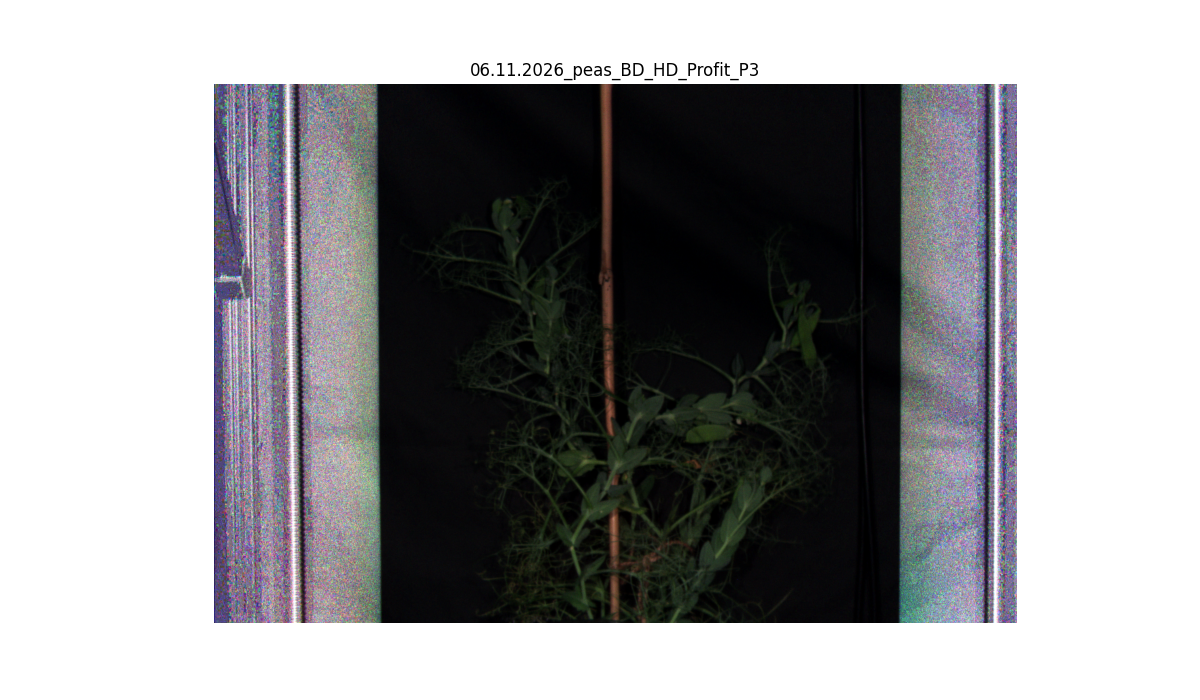

In [28]:
SAMPLE_INDEX=23
OBJECT_ID=None  # e.g. 'object_01' to edit an existing mask
if all_samples:
    editor=edit_mask(all_samples[SAMPLE_INDEX],object_id=OBJECT_ID,
                     rgb_wavelengths=OPTIONS['rgb_wavelengths'],
                     sam_backend=SEGMENTATION_MODEL if SEGMENTATION_MODEL in ('sam','sam2','sam3') else 'sam')
else:print('No corrected cubes yet. Run Stage 1 first.')


## Stage 3 — spectra, index tables, index maps and spatial PCA

Stage 3 **does not** compute PCA across object mean spectra, K-means across objects or any multi-object index collages. These computations are performed **per observation date** in Stage 4 after decoding experimental conditions.

All four mean-spectra matrices and their four index tables are saved as XLSX in `object_analysis`:
- `spectra_mean_raw.xlsx`, `spectra_mean_raw_normalized.xlsx`
- `spectra_mean_savgol.xlsx`, `spectra_mean_savgol_normalized.xlsx`
- `indices_raw.xlsx`, `indices_raw_normalized.xlsx`, `indices_savgol.xlsx`, `indices_savgol_normalized.xlsx`
- `indices_selected.xlsx` = chosen `SPECTRAL_VARIANT`; `analysis_settings.json` records the choice.

Each spectrum is normalized by **its own finite-band mean**; NaN/nonpositive means yield NaN instead of inf. `Hue_LCh` (D65/CIE1931 2°, 400–780 nm) always uses **raw calibrated reflectance**. `CSIB=R525/R800` is an exploratory index transferred from Brassica studies; its biological meaning in wheat is not validated.

**Pixelwise maps** (and their 10-bin numeric histograms) use the original calibrated **pixel cube**, not any mean spectrum. Spatial PCA maps are also computed from the cube and their PC axes are independent between objects. Changing `SPECTRAL_VARIANT` changes mean-spectra index tables and later Stage 4 comparisons, not the raw pixel maps.


In [2]:
# Switch to noninteractive display for batch plotting, if desired:
%matplotlib inline
stage3_results={}
for study in selected_folders:
    print('ANALYSIS:',study)
    try:
        stage3_results[study.name]=analyze_study_objects(
            study,mask_mode=MASK_MODE,map_mode=MAP_MODE,
            sg_window=SG_WINDOW,sg_polyorder=SG_POLYORDER,
            n_pca_components=PCA_COMPONENTS,n_clusters='auto',
            data_type='reflectance' if OPTIONS['use_spectral_correction'] else 'signal',
            color_config_csv=COLOR_SCALE_CSV,empirical_strategy=EMPIRICAL_STRATEGY,
            indices=SELECTED_INDICES,index_preset=INDEX_PRESET,
            overwrite_maps=True,pca_maps=True,pca_map_mode=PCA_MAP_MODE,
            histogram_bins=HISTOGRAM_BINS,
            spectral_variant=SPECTRAL_VARIANT)
    except Exception as ex:
        print('ERROR',study.name,type(ex).__name__,ex)


ANALYSIS: d:\HS-heat-drought-peas_06.11.2026\data


d:\HS-heat-drought-peas_06.11.2026\hyperspectral_object_analysis.py:130: UserWarning: Mean-normalized reflectance is dimensionless shape data, not absolute reflectance; index formulas with inverse reflectance or additive constants have exploratory numerical meanings only.
  index_values=calculate_vegetation_indices(data.reset_index(),output_csv=None,
d:\HS-heat-drought-peas_06.11.2026\hyperspectral_object_analysis.py:130: UserWarning: Mean-normalized reflectance is dimensionless shape data, not absolute reflectance; index formulas with inverse reflectance or additive constants have exploratory numerical meanings only.
  index_values=calculate_vegetation_indices(data.reset_index(),output_csv=None,


Index maps: 06.11.2026_peas_BB_D_Amior_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Amior_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Amior_P3 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Cleopatra_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Cleopatra_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Cleopatra_P3 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Kadet_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Kadet_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Kadet_P3 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Profit_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Profit_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BB_D_Profit_P3 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Amior_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Amior_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Amior_P3 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Cleopatra_P1 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Cleopatra_P2 / 1 mask(s)
Index maps: 06.11.2026_peas_BD_HD_Cleopatra_P3 / 1 mas

## Optional — regenerate only numerical index maps (no collages)

Rebuild pixelwise index maps and numeric histograms from saved float16 cubes and masks. Comparative date-specific collages belong to Stage 4.


In [ ]:
# Example for a single study (uncomment):
# report=render_object_index_maps(selected_folders[0],mode='union',
#     indices=SELECTED_INDICES,
#     data_type='reflectance',scale_config=COLOR_SCALE_CSV,
#     empirical_strategy='robust',overwrite=True,
#     histogram_bins=HISTOGRAM_BINS)
# display(report.head())


## Stage 4 — compare genotypes and environments **separately for each observation date**

Run only after Stage 3 and enter **matching parallel lists** `genotypes_codes/display`, `environment_codes/display`, `dates_codes/display`. Codes are matched case-insensitively as substrings of **sample folder names**. A sample must match exactly one code in every dimension, otherwise it is excluded and reported in `experiment_objects.xlsx`.

For each date the stage generates:
- `object_analysis/by_date/<date_code>/collages/collage_<index>.png` — genotype rows × environment columns, with human-readable display labels;
- `.../spectra_by_genotype_environment.png` — genotype subplots and environment lines, shaded ± sample SD across **object masks**;
- `.../group_spectrum_stats.xlsx` — reproducible numerical group mean, SD and n;
- `.../index_boxplots/<index>.png` — per-index boxplots with overlaid individual object points;
- `.../pca/objects_pca.png` and PCA scores/loadings/variance and optional K-means diagnostics in XLSX;
- `.../index_observations.xlsx` — rows with source IDs, decoded conditions, and selected indices.

**Statistics caution:** each object mask is a plotted observation, **not automatically an independent biological replicate**. Multiple masks on the same plant, technical images and pixels cannot be treated as independent plants without explicit experiment metadata. These plots are exploratory/descriptive; do not interpret them as confirmatory significance tests.

The PCA model is fitted independently for each observation date. Its component axes and scores are not directly comparable between dates. All group labels in figures use corresponding `_display` entries.


In [3]:
from experiment_comparative_analysis import analyze_experiment_by_date

genotypes_codes = ['Amior', 'Cleopatra', 'Kadet', 'Profit']
genotypes_display = ['Амиор', 'Клеопатра', 'Кадет', 'Профит']
environment_codes = ['BB_D', 'BD_HD']
environment_display = ['холод-засуха', 'жара-засуха']
# Examples: your sample folder names must contain exactly one date code.
dates_codes = ['06.11.2026']
dates_display = ['06.11.2026']

for study in selected_folders:
    print('DATE-WISE COMPARISON:', study)
    try:
        result = analyze_experiment_by_date(
            study,
            genotypes_codes=genotypes_codes,
            genotypes_display=genotypes_display,
            environment_codes=environment_codes,
            environment_display=environment_display,
            dates_codes=dates_codes,
            dates_display=dates_display,
            indices=SELECTED_INDICES,
            spectral_variant=SPECTRAL_VARIANT,
            per_cell_columns=3,
            create_collages=True,
            pca_scaling='center',  # or 'standardize'
            overwrite=True,
        )
        print(result.to_string(index=False))
    except Exception as ex:
        print('ERROR grouped analysis:', study.name, type(ex).__name__, ex)


DATE-WISE COMPARISON: d:\HS-heat-drought-peas_06.11.2026\data
Sorted source maps: 528 copied for date 06.11.2026
Sorted collage: collage_NDVI.png
Sorted collage: collage_NDRE.png
Sorted collage: collage_PRI.png
Sorted collage: collage_PSRI.png
Sorted collage: collage_ARI2.png
Sorted collage: collage_CRI2.png
Sorted collage: collage_WBI.png
Sorted collage: collage_OSAVI.png
Sorted collage: collage_GNDVI.png
Sorted collage: collage_CIgreen.png
Sorted collage: collage_CIrededge.png
Sorted collage: collage_NDVI705.png
Sorted collage: collage_MTCI.png
Sorted collage: collage_SIPI.png
Sorted collage: collage_REP.png
Sorted collage: collage_mND705.png
Sorted collage: collage_TCARI_OSAVI.png
Sorted collage: collage_MSAVI.png
Sorted collage: collage_CSIB.png
Sorted collage: collage_EWRI_410_900.png
Sorted collage: collage_EWRI_410_950.png
Sorted collage: collage_Hue_LCh.png
Completed date 06.11.2026: 24 object masks, 22 index plots
 date_code date_display  n_object_masks  n_samples  n_indices s